# Land use regression results

Post-processing and visualization of land use regression results.


In [1]:
import contextily as cx
import libpysal
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr
from libpysal.weights import KNN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from focalpy import utils
from zurich_uhi_lur import plot_utils, regr_utils

plot_utils.set_style()

In [2]:
# input data paths
stations_gdf_filepath = "../data/processed/stations.gpkg"
station_features_filepath = "../data/processed/stations-features.csv"
ts_df_filepath = "../data/processed/ts-df.csv"
grid_gdf_filepath = "../data/processed/regular-grid.gpkg"
grid_features_filepath = "../data/processed/grid-features.csv"

# LUR results
dst_results_filepath = "../data/processed/lur-results.csv"
dst_importance_filepath = "../data/processed/lur-importance.csv"
obs_pred_data_filepath = "../data/processed/lur-obs-pred.csv"
grid_pred_filepath = "../data/processed/lur-grid-pred.nc"
grid_pred_pct_filepath = "../data/processed/lur-grid-pred-pct.csv"

# output figures
dst_scores_performance_filepath = "../reports/figures/lur-scores-performance.pdf"
dst_rsa_filepath = "../reports/figures/lur-rsa.pdf"
dst_shap_filepath = "../data/processed/lur-shap.csv"
dst_maps_filepath = "../reports/figures/lur-maps.png"
dst_pca_filepath = "../reports/figures/lur-pca.pdf"
dst_pca_loadings_filepath = "../reports/figures/lur-pca-loadings.pdf"
dst_pred_spread_filepath = "../reports/figures/lur-pred-spread.pdf"

# experiment settings (must match lur-model)
# hour of the day (local time)
target_hour = 23
fracs = [0, 0.33, 0.66, 1]
seed = 0
n_reps = 5


# how to get model keys programmatically?
MODEL_KEYS = ["MLR", "GAM", "RF"]

In [3]:
# Parameters
stations_gdf_filepath = "data/processed/stations.gpkg"
station_features_filepath = "data/processed/stations-features.csv"
ts_df_filepath = "data/processed/ts-df.csv"
grid_gdf_filepath = "data/processed/regular-grid.gpkg"
grid_features_filepath = "data/processed/grid-features.csv"
dst_results_filepath = "data/processed/lur-results.csv"
dst_importance_filepath = "data/processed/lur-importance.csv"
obs_pred_data_filepath = "data/processed/lur-obs-pred.csv"
dst_shap_filepath = "data/processed/lur-shap.csv"
grid_pred_filepath = "data/processed/lur-grid-pred.nc"
grid_pred_pct_filepath = "data/processed/lur-grid-pred-pct.csv"
dst_scores_performance_filepath = "reports/figures/lur-scores-performance.pdf"
dst_rsa_filepath = "reports/figures/lur-rsa.pdf"
dst_maps_filepath = "reports/figures/lur-maps.png"
dst_pca_filepath = "reports/figures/lur-pca.pdf"
dst_pca_loadings_filepath = "reports/figures/lur-pca-loadings.pdf"
dst_pred_spread_filepath = "reports/figures/lur-pred-spread.pdf"


## Load results


In [4]:
results_df = pd.read_csv(dst_results_filepath)
importance_df = pd.read_csv(dst_importance_filepath)
shap_df = pd.read_csv(dst_shap_filepath)
obs_pred_df = pd.read_csv(obs_pred_data_filepath)

# Grid prediction maps come from the aggregated raster written by lur-model
# (mean/std over the LCS-subsampling reps), so no fitted pipelines are loaded here.
grid_pred_ds = xr.open_dataset(grid_pred_filepath)

print(
    f"Loaded {len(results_df)} result rows, "
    f"{len(importance_df)} importance rows, {len(shap_df)} shap rows"
)
print(f"Grid predictions: {dict(grid_pred_ds.sizes)}")

Loaded 60 result rows, 144 importance rows, 21502 shap rows
Grid predictions: {'model': 3, 'frac': 4, 'y': 146, 'x': 158}


In [5]:
station_features_gdf = regr_utils.get_site_features_gdf(
    station_features_filepath,
    stations_gdf_filepath,
)
aws_gdf = station_features_gdf[station_features_gdf["source"] == "AWS"]
lcs_gdf = station_features_gdf[station_features_gdf["source"] == "LCS"]

grid_features_gdf = regr_utils.get_site_features_gdf(
    grid_features_filepath,
    grid_gdf_filepath,
)

## Postprocessing

### Model performance and residual spatial autocorrelation

**Figures: cross-validated performance across LCS fractions** (`lur-scores-performance.pdf`).

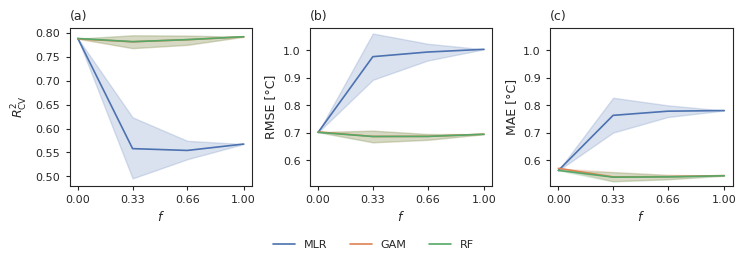

In [6]:
# the figure spans the widened text block of the article, drawn at its printed size
PANEL_HEIGHT = 2.5  # in, including the legend row

# Per-rep RMSE and MAE from obs_pred_df so sns.lineplot can show CI across reps
error_df = (
    obs_pred_df.assign(
        sq_error=lambda d: (d["pred"] - d["obs"]) ** 2,
        abs_error=lambda d: (d["pred"] - d["obs"]).abs(),
    )
    .groupby(["model", "frac", "rep"])
    .agg(rmse=("sq_error", lambda x: np.sqrt(x.mean())), mae=("abs_error", "mean"))
    .reset_index()
)
plot_df = results_df.merge(error_df, on=["model", "frac", "rep"])

palette = dict(zip(MODEL_KEYS, sns.color_palette(n_colors=len(MODEL_KEYS))))
model_handles = [plt.Line2D([], [], color=palette[m], label=m) for m in MODEL_KEYS]

perf_labels = {
    "r2_cv": r"$R^2_{\mathrm{CV}}$",
    "rmse": "RMSE [°C]",
    "mae": "MAE [°C]",
}
fig, axes = plt.subplots(
    1,
    len(perf_labels),
    figsize=(plot_utils.WIDE_TEXT_WIDTH, PANEL_HEIGHT),
    layout="constrained",
)
for ax, (metric, label) in zip(axes, perf_labels.items()):
    sns.lineplot(
        data=plot_df,
        x="frac",
        y=metric,
        hue="model",
        hue_order=MODEL_KEYS,
        palette=palette,
        errorbar=("ci", 95),
        seed=seed,
        ax=ax,
        legend=False,
    )
    ax.set_xticks(fracs)
    ax.set_xlabel("$f$")
    ax.set_ylabel(label)
# RMSE and MAE share a common y range so that the two errors can be compared directly
error_axes = axes[1:]
error_ylim = (
    min(ax.get_ylim()[0] for ax in error_axes),
    max(ax.get_ylim()[1] for ax in error_axes),
)
error_axes[1].sharey(error_axes[0])
error_axes[0].set_ylim(error_ylim)
fig.legend(
    handles=model_handles,
    loc="outside lower center",
    ncol=len(MODEL_KEYS),
    frameon=False,
)
plot_utils.label_panels(axes)
fig.savefig(dst_scores_performance_filepath)

### Spatial station coverage per LCS fraction

**Figure: station coverage of the predictor feature space, as a PCA of the grid predictors** (`lur-pca.pdf`).

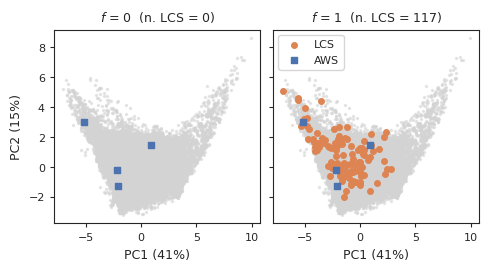

In [7]:
X_grid = grid_features_gdf.drop(columns=["geometry", "source"], errors="ignore")

sample_per_frac = {
    fracs[0]: aws_gdf.drop(columns="source"),
    # the LCS co-located with the Zurich-Kaserne AWS is excluded from training
    fracs[-1]: pd.concat([aws_gdf, lcs_gdf])
    .drop(columns="source")
    .drop(index="534", errors="ignore"),
}
plot_fracs = [fracs[0], fracs[-1]]

# Fit PCA on the grid — defines the reference variance landscape
scaler_pca = StandardScaler()
X_grid_scaled = scaler_pca.fit_transform(X_grid.values)
pca = PCA(n_components=2).fit(X_grid_scaled)
# ACHTUNG: the sign of each component is arbitrary and can flip when the predictor set
# changes, so orient both by their building volume (500 m) loading, i.e., built-up areas
# at low PC1 and high PC2, to keep the figures and their description stable
orient_col = X_grid.columns.get_loc("building_volume_sum_500")
pca.components_ *= np.where(pca.components_[:, orient_col] > 0, [-1, 1], [1, -1])[
    :, np.newaxis
]
grid_pcs = pca.transform(X_grid_scaled)
var_exp = pca.explained_variance_ratio_

# the scatter and loadings panels are printed side by side at 0.65 and 0.34 of the
# widened text block, sharing their printed height
PCA_HEIGHT = 2.6  # in

fig, axes = plt.subplots(
    1,
    len(plot_fracs),
    figsize=(0.65 * plot_utils.WIDE_TEXT_WIDTH, PCA_HEIGHT),
    layout="constrained",
    sharex=True,
    sharey=True,
)

for ax, frac in zip(axes, plot_fracs):
    ax.scatter(
        grid_pcs[:, 0],
        grid_pcs[:, 1],
        c="lightgrey",
        s=2,
        alpha=0.5,
        zorder=0,
        rasterized=True,
    )

    sample_gdf = sample_per_frac[frac]
    X_sample = sample_gdf.drop(columns="geometry").reindex(columns=X_grid.columns)
    sample_pcs = pca.transform(scaler_pca.transform(X_sample.values))

    aws_mask = sample_gdf.index.isin(aws_gdf.index)
    ax.scatter(
        sample_pcs[~aws_mask, 0],
        sample_pcs[~aws_mask, 1],
        c="C1",
        s=16,
        zorder=2,
        label="LCS",
    )
    ax.scatter(
        sample_pcs[aws_mask, 0],
        sample_pcs[aws_mask, 1],
        c="C0",
        marker="s",
        s=22,
        zorder=3,
        label="AWS",
    )

    n_lcs = (~aws_mask).sum()
    ax.set_title(f"$f$ = {frac}  (n. LCS = {n_lcs})")
    ax.set_xlabel(f"PC1 ({var_exp[0]:.0%})")

axes[0].set_ylabel(f"PC2 ({var_exp[1]:.0%})")

axes[-1].legend(loc="best")
fig.savefig(dst_pca_filepath)

#### PCA loadings

**Figure: loadings of the first two principal components** (`lur-pca-loadings.pdf`).

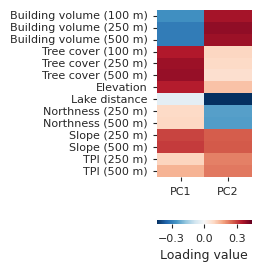

In [8]:
pca_feature_labels = {
    "building_volume_sum_100": "Building volume (100 m)",
    "building_volume_sum_250": "Building volume (250 m)",
    "building_volume_sum_500": "Building volume (500 m)",
    "tree_sum_100": "Tree cover (100 m)",
    "tree_sum_250": "Tree cover (250 m)",
    "tree_sum_500": "Tree cover (500 m)",
    "elevation_0": "Elevation",
    "lake_distance_0": "Lake distance",
    "aspect_northness_250": "Northness (250 m)",
    "aspect_northness_500": "Northness (500 m)",
    "slope_mean_250": "Slope (250 m)",
    "slope_mean_500": "Slope (500 m)",
    "topographic_position_index_250": "TPI (250 m)",
    "topographic_position_index_500": "TPI (500 m)",
}

loading_df = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i + 1}" for i in range(pca.n_components_)],
    index=X_grid.columns,
).rename(index=pca_feature_labels)
max_abs = max(abs(loading_df.min().min()), loading_df.max().max())

fig, ax = plt.subplots(
    figsize=(0.34 * plot_utils.WIDE_TEXT_WIDTH, PCA_HEIGHT), layout="constrained"
)
sns.heatmap(
    loading_df,
    cmap="RdBu_r",
    vmin=-max_abs,
    vmax=max_abs,
    # with 14 predictors seaborn's automatic tick thinning would otherwise drop half
    # the row labels at this panel height
    yticklabels=True,
    # a horizontal colorbar below leaves the width of the narrow panel to the heatmap
    cbar_kws={"label": "Loading value", "orientation": "horizontal", "pad": 0.12},
    ax=ax,
)
# three ticks, so that their labels do not run into each other at the printed width
ax.collections[0].colorbar.set_ticks([-0.3, 0, 0.3])
fig.savefig(dst_pca_loadings_filepath)

### Observed vs predicted

**Figure: observed versus predicted temperature anomalies per model and LCS fraction**, for the first repetition (shown in the notebook only).

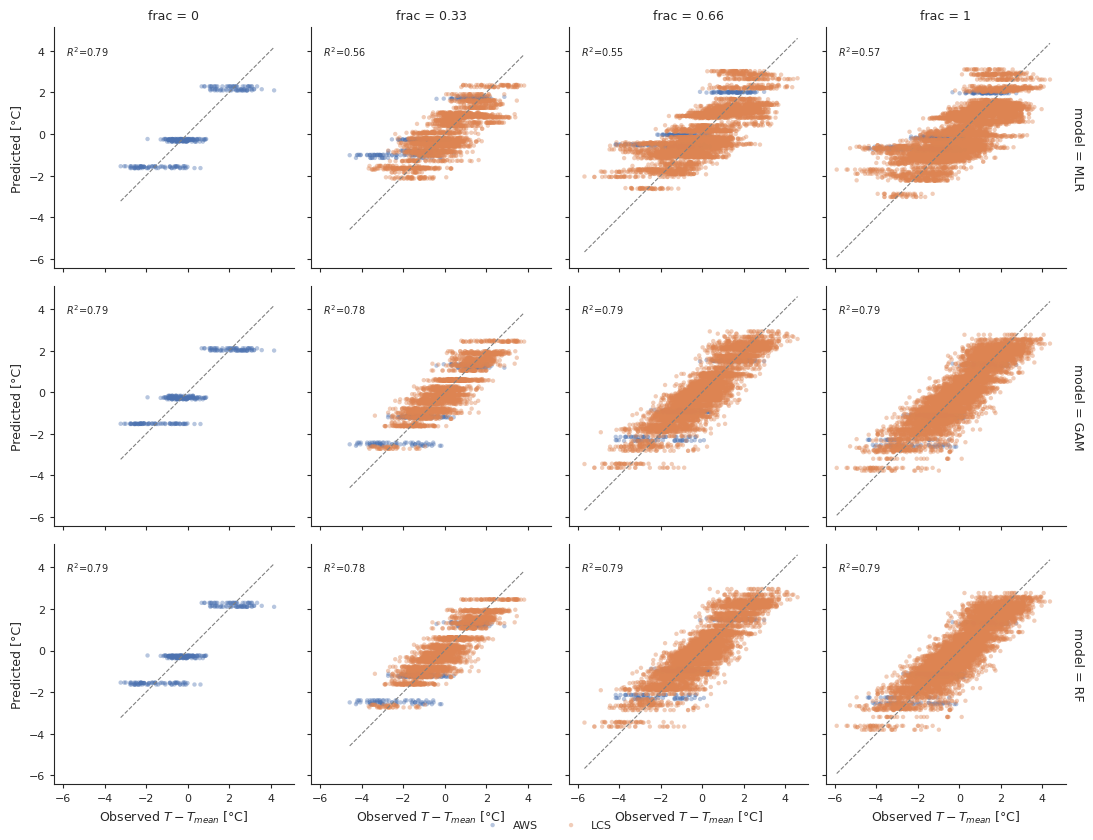

In [9]:
# Show rep=0 for each frac: one representative sample, avoids overplotting multiple reps
plot_df = obs_pred_df[obs_pred_df["rep"] == 0].copy()

g = sns.FacetGrid(
    plot_df,
    row="model",
    col="frac",
    col_order=fracs,
    row_order=MODEL_KEYS,
    hue="source",
    palette={"AWS": "C0", "LCS": "C1"},
    height=2.8,
    aspect=1,
    sharex=True,
    sharey=True,
    margin_titles=True,
)
g.map(plt.scatter, "obs", "pred", alpha=0.4, s=10, edgecolors="none")

# identity line and per-panel R²_cv annotation
for (row_val, col_val), ax in g.axes_dict.items():
    sub = plot_df.query("model == @row_val and frac == @col_val")
    lo = min(sub["obs"].min(), sub["pred"].min())
    hi = max(sub["obs"].max(), sub["pred"].max())
    ax.plot([lo, hi], [lo, hi], color="gray", linewidth=0.8, linestyle="--")
    r2_val = results_df.query("model == @row_val and frac == @col_val")["r2_cv"].mean()
    ax.text(
        0.05,
        0.93,
        f"$R^2$={r2_val:.2f}",
        transform=ax.transAxes,
        fontsize=7,
        va="top",
    )

g.set_axis_labels("Observed $T - T_{mean}$ [°C]", "Predicted [°C]")
g.add_legend(title="")
sns.move_legend(g, "lower center", ncol=2)

### Moran scatterplots (OOF residuals)

**Figure: Moran scatterplots of the out-of-fold residuals** (`lur-rsa.pdf`).

MLR: OLS slope = +0.1970 | Moran's I = +0.1970
GAM: OLS slope = +0.0186 | Moran's I = +0.0186
RF: OLS slope = -0.0016 | Moran's I = -0.0016


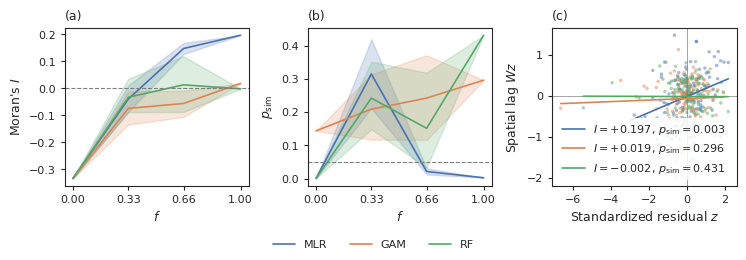

In [10]:
# Residual spatial autocorrelation: Moran's I and its permutation p-value across LCS
# fractions, plus a Moran scatterplot of the out-of-fold residuals at f=1 with the
# three models overlaid. In the standard orientation (centred and standardised
# residual z on x, its spatial lag Wz on y) the OLS slope of each cloud is Moran's I,
# so the lines are directly comparable across models.
# ACHTUNG: station 534 was excluded from training in lur-model and is therefore absent
# from obs_pred_df; it is also excluded here from the KNN weights.
station_gdf_moran = pd.concat([aws_gdf, lcs_gdf]).drop(columns="source")
station_gdf_moran = station_gdf_moran[station_gdf_moran.index != "534"]
station_gser_moran = station_gdf_moran["geometry"]

coords = utils.as_coord_arr(station_gser_moran)
w_moran = KNN(coords, k=4)
w_moran.transform = "r"
station_ids = station_gser_moran.index  # order matches coords / spatial weights

moran_frac1 = (
    results_df[np.isclose(results_df["frac"], 1)]
    .groupby("model")[["moran_I", "moran_p_sim"]]
    .mean()
)

rsa_labels = {"moran_I": r"Moran's $I$", "moran_p_sim": r"$p_{\mathrm{sim}}$"}
rsa_reflines = {"moran_I": 0.0, "moran_p_sim": 0.05}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(plot_utils.WIDE_TEXT_WIDTH, PANEL_HEIGHT),
    layout="constrained",
)
for ax, (metric, label) in zip(axes[:2], rsa_labels.items()):
    sns.lineplot(
        data=results_df,
        x="frac",
        y=metric,
        hue="model",
        hue_order=MODEL_KEYS,
        palette=palette,
        errorbar=("ci", 95),
        seed=seed,
        ax=ax,
        legend=False,
    )
    ax.axhline(rsa_reflines[metric], color="0.5", linestyle="--", linewidth=0.8)
    ax.set_xticks(fracs)
    ax.set_xlabel("$f$")
    ax.set_ylabel(label)

ax = axes[2]
ax.axhline(0, color="0.5", linewidth=0.5)
ax.axvline(0, color="0.5", linewidth=0.5)
for model_key in MODEL_KEYS:
    op_df = obs_pred_df.query("model == @model_key and frac == 1 and rep == 0")
    resid_ser = (op_df["obs"] - op_df["pred"]).groupby(op_df["station_id"]).mean()
    z_arr = resid_ser.reindex(station_ids).values
    # centred and standardised, so that the OLS slope of the lag on z is Moran's I
    z_arr = (z_arr - z_arr.mean()) / z_arr.std()
    lag_arr = libpysal.weights.lag_spatial(w_moran, z_arr)
    slope, intercept = np.polyfit(z_arr, lag_arr, 1)
    I_val, p_val = moran_frac1.loc[model_key, ["moran_I", "moran_p_sim"]]
    print(f"{model_key}: OLS slope = {slope:+.4f} | Moran's I = {I_val:+.4f}")
    ax.scatter(
        z_arr,
        lag_arr,
        s=6,
        alpha=0.5,
        color=palette[model_key],
        edgecolors="none",
    )
    xs = np.array([z_arr.min(), z_arr.max()])
    ax.plot(
        xs,
        intercept + slope * xs,
        color=palette[model_key],
        label=rf"$I = {I_val:+.3f}$, $p_{{\mathrm{{sim}}}} = {p_val:.3f}$",
    )
ax.set_xlabel(r"Standardized residual $z$")
ax.set_ylabel(r"Spatial lag $Wz$")
# the lower left of the panel is empty, since the residuals cluster around zero
ax.legend(loc="lower left", frameon=True, framealpha=0.85, edgecolor="none")

fig.legend(
    handles=model_handles,
    loc="outside lower center",
    ncol=len(MODEL_KEYS),
    frameon=False,
)
plot_utils.label_panels(axes)
fig.savefig(dst_rsa_filepath)

### Feature importances

**Figure: per-model feature importances across LCS fractions** for all predictors (shown in the notebook only), the full version of the reduced figure produced by the `lur-importance-figures` notebook.

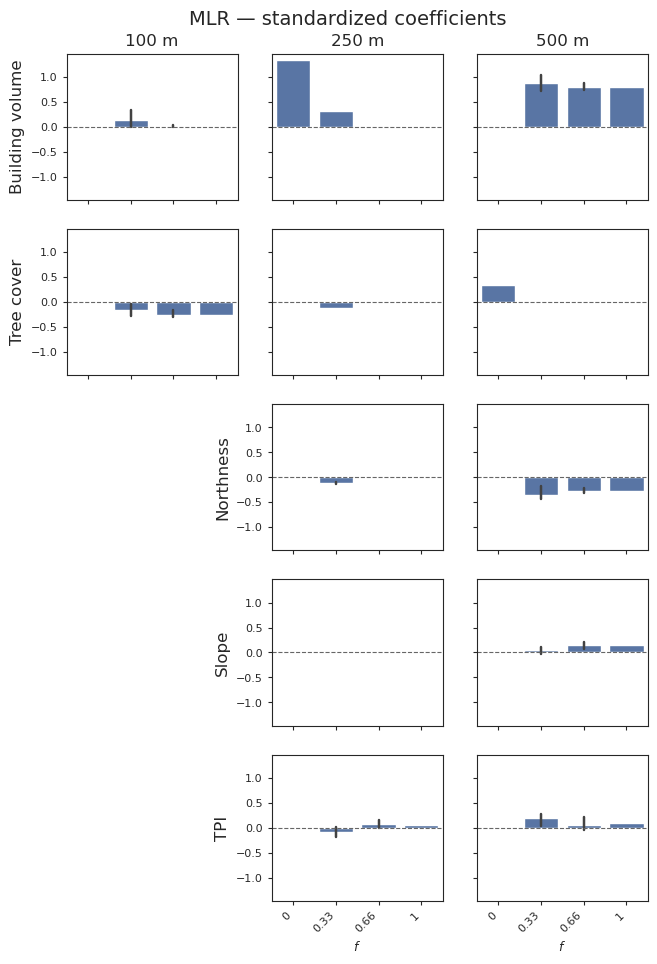

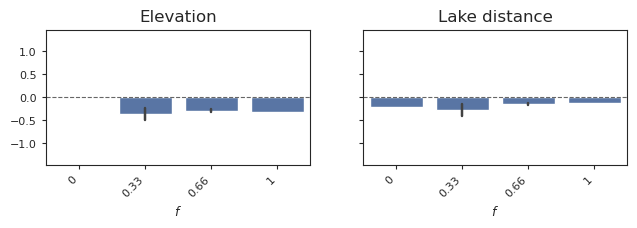

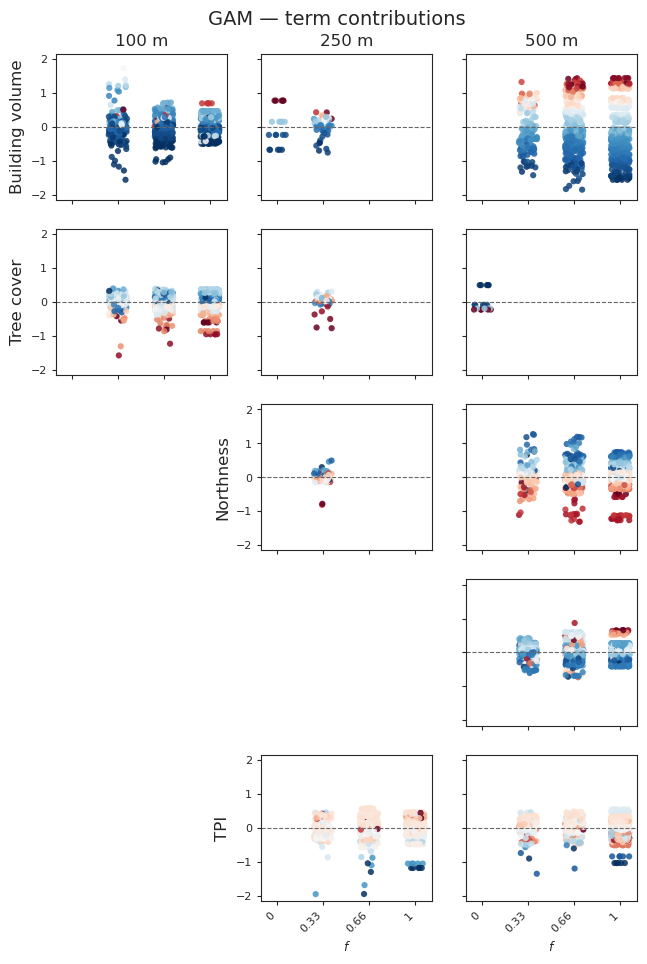

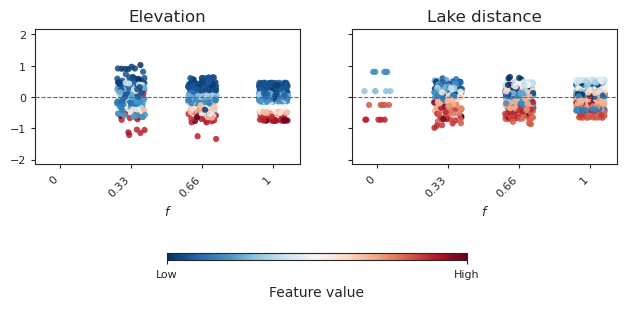

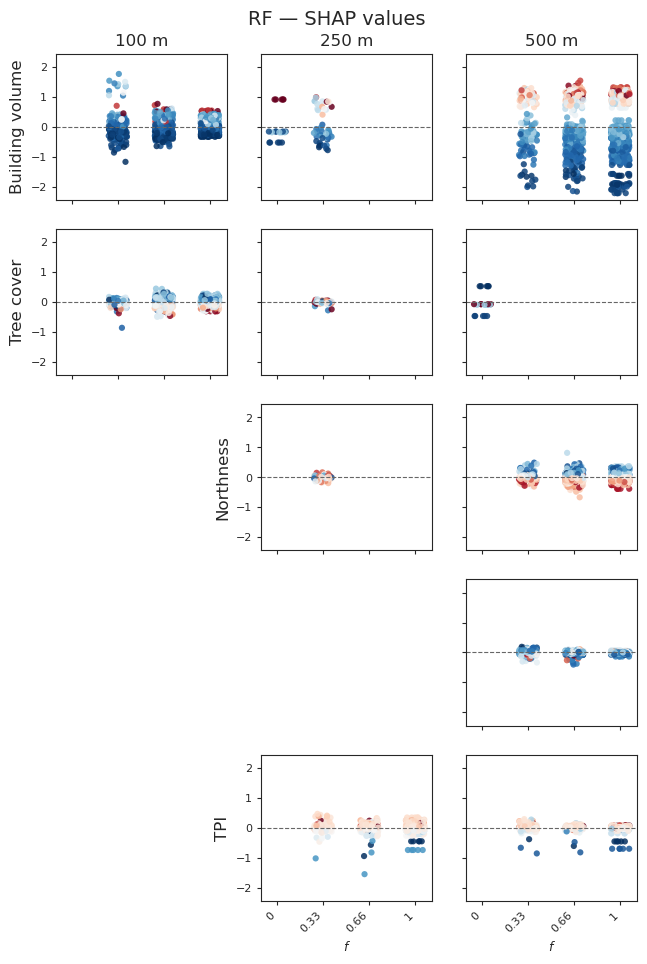

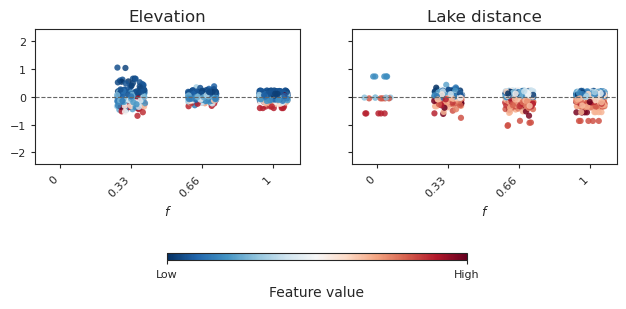

In [11]:
SCALE_TO_COL = {100: 0, 250: 1, 500: 2}
multi_scale_groups = [
    (
        "Building volume",
        [
            "building_volume_sum_100",
            "building_volume_sum_250",
            "building_volume_sum_500",
        ],
    ),
    ("Tree cover", ["tree_sum_100", "tree_sum_250", "tree_sum_500"]),
    ("Northness", ["aspect_northness_250", "aspect_northness_500"]),
    ("Slope", ["slope_mean_250", "slope_mean_500"]),
    (
        "TPI",
        ["topographic_position_index_250", "topographic_position_index_500"],
    ),
]
single_scale_groups = [
    ("Elevation", ["elevation_0"]),
    ("Lake distance", ["lake_distance_0"]),
]
frac_order = list(fracs)
MULTI_SCALE_FIGSIZE = (7.5, 11.0)
SINGLE_SCALE_FIGSIZE = (7.5, 3.0)
# Shared layout for single-scale panels so MLR and GAM/RF axes align vertically
SINGLE_SCALE_LAYOUT = dict(top=0.85, bottom=0.40)


def _compute_model_ylim(model_name, padding=0.1):
    """Symmetric ylim around 0 so positive/negative importances are equally visible."""
    data = importance_df.query("model == @model_name")["value"]
    max_abs = max(abs(data.min()), abs(data.max()))
    val = max_abs * (1 + padding)
    return (-val, val)


def _compute_shap_ylim(model_name, padding=0.1):
    data = shap_df.query("model == @model_name")["shap_value"]
    max_abs = max(abs(data.min()), abs(data.max()))
    return (-(max_abs * (1 + padding)), max_abs * (1 + padding))


# Per-feature value range for consistent beeswarm coloring across fracs
_feat_vranges = (
    shap_df.groupby("feature")["feature_value"]
    .agg(vmin="min", vmax="max")
    .to_dict("index")
)


def _barplot_feature(ax, plot_df, feature, color):
    sns.barplot(
        data=plot_df.query("feature == @feature"),
        x="frac",
        y="value",
        order=frac_order,
        estimator="mean",
        errorbar=("ci", 95),
        color=color,
        ax=ax,
    )
    ax.axhline(0, color="0.4", linestyle="--", linewidth=0.8)


def _beeswarm_feature(ax, plot_df, feature, ylim):
    data = plot_df.query("feature == @feature")
    if data.empty:
        ax.set_visible(False)
        return
    vmin = _feat_vranges.get(feature, {}).get("vmin", data["feature_value"].min())
    vmax = _feat_vranges.get(feature, {}).get("vmax", data["feature_value"].max())
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    rng = np.random.default_rng(42)
    for frac_idx, frac in enumerate(frac_order):
        sub = data[np.isclose(data["frac"], frac)]
        if sub.empty:
            continue
        colors = plt.cm.RdBu_r(norm(sub["feature_value"].values))
        x_jitter = rng.uniform(-0.2, 0.2, len(sub))
        ax.scatter(
            frac_idx + x_jitter,
            sub["shap_value"].values,
            c=colors,
            s=20,
            alpha=0.85,
            linewidths=0,
        )
    ax.axhline(0, color="0.4", linestyle="--", linewidth=0.8)
    ax.set_ylim(ylim)
    ax.set_xticks(range(len(frac_order)))
    ax.set_xticklabels([f"{f:g}" for f in frac_order], rotation=45, ha="right")


def _plot_multi_scale_importance(model_name, color, title, ylim):
    """Multi-scale figure: columns aligned by buffer distance (100/250/500 m).

    Features without a 100 m scale (Aspect, Slope, TPI) are pushed right so
    250 m always falls in col 1 and 500 m in col 2. The feature name is the
    ylabel on the leftmost visible column of each row. All axes share the same
    y range (symmetric around 0) so features can be compared directly.
    """
    plot_df = importance_df.query("model == @model_name").copy()
    n_rows = len(multi_scale_groups)
    n_cols = len(SCALE_TO_COL)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=MULTI_SCALE_FIGSIZE,
        squeeze=False,
        sharex=True,
    )
    fig.suptitle(title, fontsize=14, y=0.92)

    for row_idx, (group_label, group_features) in enumerate(multi_scale_groups):
        is_last_row = row_idx == n_rows - 1
        feat_by_scale = {int(f.rsplit("_", 1)[-1]): f for f in group_features}
        first_col = SCALE_TO_COL[min(feat_by_scale)]

        for scale, col_idx in SCALE_TO_COL.items():
            ax = axes[row_idx, col_idx]
            if scale not in feat_by_scale:
                ax.set_visible(False)
                continue

            _barplot_feature(ax, plot_df, feat_by_scale[scale], color)
            ax.set_ylim(ylim)
            ax.set_title(f"{scale} m" if row_idx == 0 else "", fontsize=12)

            if col_idx == first_col:
                ax.set_ylabel(group_label, fontsize=12)
            else:
                ax.set_ylabel("")
                ax.tick_params(labelleft=False)

            if is_last_row:
                ax.set_xlabel("$f$")
                ax.set_xticks(range(len(frac_order)))
                ax.set_xticklabels(
                    [f"{f:g}" for f in frac_order], rotation=45, ha="right"
                )
            else:
                ax.set_xlabel("")

    return fig


def _plot_single_scale_importance(model_name, color, title, ylim):
    """Single-scale figure: elevation and lake distance in one row, same ylim."""
    plot_df = importance_df.query("model == @model_name").copy()
    n_groups = len(single_scale_groups)

    fig, axes = plt.subplots(
        1,
        n_groups,
        figsize=SINGLE_SCALE_FIGSIZE,
        squeeze=False,
        sharex=True,
    )
    fig.subplots_adjust(**SINGLE_SCALE_LAYOUT)

    for col_idx, (group_label, group_features) in enumerate(single_scale_groups):
        ax = axes[0, col_idx]
        _barplot_feature(ax, plot_df, group_features[0], color)
        ax.set_ylim(ylim)
        ax.set_title(group_label, fontsize=12)
        ax.set_xlabel("$f$")
        ax.set_xticks(range(len(frac_order)))
        ax.set_xticklabels([f"{f:g}" for f in frac_order], rotation=45, ha="right")
        ax.set_ylabel("")
        if col_idx > 0:
            ax.tick_params(labelleft=False)

    return fig


def _plot_multi_scale_beeswarm(model_name, title, ylim):
    plot_df = shap_df.query("model == @model_name").copy()
    n_rows = len(multi_scale_groups)
    n_cols = len(SCALE_TO_COL)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=MULTI_SCALE_FIGSIZE,
        squeeze=False,
        sharex=True,
    )
    fig.suptitle(title, fontsize=14, y=0.92)

    for row_idx, (group_label, group_features) in enumerate(multi_scale_groups):
        feat_by_scale = {int(f.rsplit("_", 1)[-1]): f for f in group_features}
        first_col = SCALE_TO_COL[min(feat_by_scale)]
        is_last_row = row_idx == n_rows - 1

        for scale, col_idx in SCALE_TO_COL.items():
            ax = axes[row_idx, col_idx]
            if scale not in feat_by_scale:
                ax.set_visible(False)
                continue

            _beeswarm_feature(ax, plot_df, feat_by_scale[scale], ylim)
            ax.set_title(f"{scale} m" if row_idx == 0 else "", fontsize=12)

            if col_idx == first_col:
                ax.set_ylabel(group_label, fontsize=12)
            else:
                ax.set_ylabel("")
                ax.tick_params(labelleft=False)

            if is_last_row:
                ax.set_xlabel("$f$")
            else:
                ax.set_xlabel("")
                ax.set_xticklabels([])

    return fig


def _plot_single_scale_beeswarm(model_name, title, ylim):
    plot_df = shap_df.query("model == @model_name").copy()
    n_groups = len(single_scale_groups)

    fig, axes = plt.subplots(
        1,
        n_groups,
        figsize=SINGLE_SCALE_FIGSIZE,
        squeeze=False,
        sharex=True,
    )
    fig.subplots_adjust(**SINGLE_SCALE_LAYOUT)

    for col_idx, (group_label, group_features) in enumerate(single_scale_groups):
        ax = axes[0, col_idx]
        _beeswarm_feature(ax, plot_df, group_features[0], ylim)
        ax.set_title(group_label, fontsize=12)
        ax.set_xlabel("$f$")
        ax.set_ylabel("")
        if col_idx > 0:
            ax.tick_params(labelleft=False)

    cbar_ax = fig.add_axes([0.3, 0.08, 0.4, 0.025])
    sm = plt.cm.ScalarMappable(cmap="RdBu_r", norm=plt.Normalize(0, 1))
    sm.set_array([])
    cb = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
    cb.set_ticks([0, 1])
    cb.set_ticklabels(["Low", "High"])
    cb.set_label("Feature value", fontsize=10)

    return fig


# MLR: barplot, one figure per model (frac on x-axis)
ylim_mlr = _compute_model_ylim("MLR")
for func in [_plot_multi_scale_importance, _plot_single_scale_importance]:
    func("MLR", "C0", "MLR — standardized coefficients", ylim=ylim_mlr)

# GAM, RF: beeswarm, one figure per model (frac groups on x-axis)
shap_model_configs = {
    "GAM": ("C2", "GAM — term contributions"),
    "RF": ("C1", "RF — SHAP values"),
}
for model_name, (color, title) in shap_model_configs.items():
    ylim = _compute_shap_ylim(model_name)
    for func in [_plot_multi_scale_beeswarm, _plot_single_scale_beeswarm]:
        func(model_name, title, ylim)

### Grid prediction maps

**Figure: mean predicted temperature anomaly maps per model and LCS fraction** (`lur-maps.png`).

**Figure: per-cell standard deviation of the predictions across repetitions**, quantifying the sensitivity to the specific LCS subset drawn (shown in the notebook only).

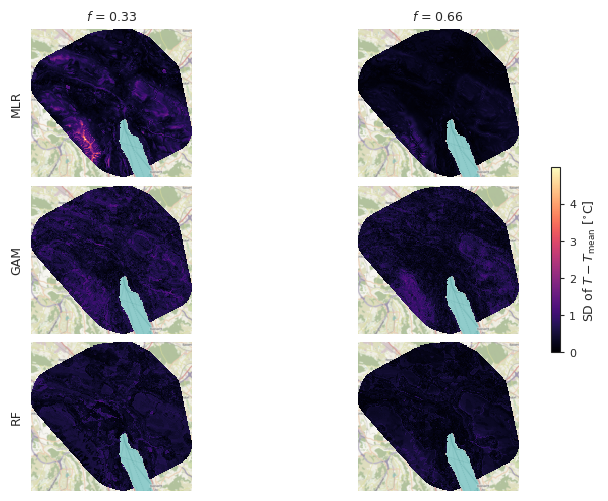

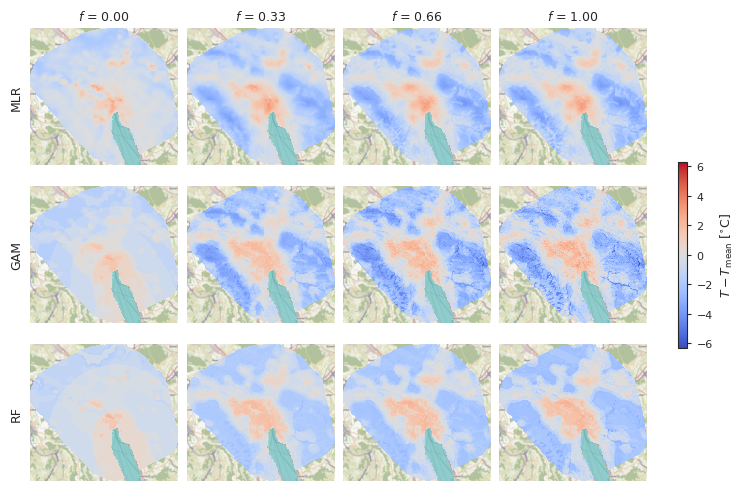

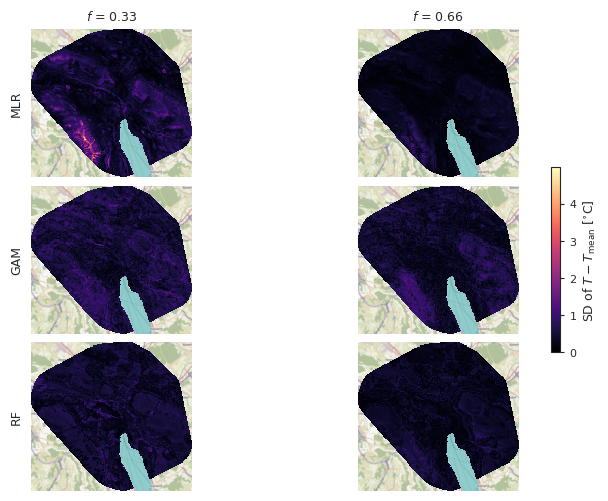

In [12]:
pred_label = r"$T - T_{\mathrm{mean}}$ [$^{\circ}$C]"

pred_mean = grid_pred_ds["pred_mean"]
pred_std = grid_pred_ds["pred_std"]

# the map grid spans the widened text block of the article, drawn at its printed size
MAPS_HEIGHT = 4.9  # in


def _draw_maps(da, *, cmap, vmin, vmax, cbar_label, dst_filepath=None):
    fig, axes = plt.subplots(
        da.sizes["model"],
        da.sizes["frac"],
        figsize=(plot_utils.WIDE_TEXT_WIDTH, MAPS_HEIGHT),
        layout="constrained",
        squeeze=False,
    )
    for row, model_key in enumerate(da["model"].values):
        for col, frac in enumerate(da["frac"].values):
            ax = axes[row, col]
            mesh = da.sel(model=model_key, frac=frac).plot.pcolormesh(
                ax=ax,
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
                add_colorbar=False,
                add_labels=False,
            )
            ax.set_aspect("equal")
            ax.set_axis_off()
            cx.add_basemap(ax, crs=grid_features_gdf.crs, attribution=False)
            if row == 0:
                ax.set_title(f"$f$ = {frac:.2f}")
            if col == 0:
                # set_axis_off() hides plain ylabels, so the model is annotated instead
                ax.annotate(
                    model_key,
                    xy=(-0.05, 0.5),
                    xycoords="axes fraction",
                    rotation=90,
                    ha="right",
                    va="center",
                    fontsize=plot_utils.FONT_SIZE,
                )
    fig.colorbar(mesh, ax=axes, shrink=0.4, label=cbar_label)
    if dst_filepath is not None:
        fig.savefig(dst_filepath)
    return fig


# Mean prediction across reps, on a color scale shared by every panel
abs_max = float(np.abs(pred_mean).max())
_draw_maps(
    pred_mean,
    cmap="coolwarm",
    vmin=-abs_max,
    vmax=abs_max,
    cbar_label=pred_label,
    dst_filepath=dst_maps_filepath,
)

# Prediction spread (std) across reps = sensitivity to which LCS subset is drawn.
# Only intermediate fractions vary the sample; f=0 (AWS only) and f=1 (all LCS)
# have no subsampling, so they are omitted from the uncertainty maps.
sampling_fracs = [f for f in fracs if 0 < f < 1]
pred_std_sampling = pred_std.sel(frac=sampling_fracs)
std_max = float(pred_std_sampling.max())
_draw_maps(
    pred_std_sampling,
    cmap="magma",
    vmin=0,
    vmax=std_max,
    cbar_label=r"SD of $T - T_{\mathrm{mean}}$ [$^{\circ}$C]",
)

### Predicted temperature range against network coverage

**Figure: percentile envelope of the predicted anomaly across the grid, against the observed envelope among the training stations** (`lur-pred-spread.pdf`).


reference offset by frac: {0.0: -0.86, 0.33: -0.08, 0.66: -0.03, 1.0: 0.0}
      spread                p5               p95            
model    GAM   MLR    RF   GAM   MLR    RF   GAM   MLR    RF
frac                                                        
0.00    2.38  2.42  1.70 -2.49 -2.50 -2.07 -0.11 -0.09 -0.37
0.33    5.08  4.40  3.66 -3.68 -3.25 -2.28  1.40  1.15  1.38
0.66    5.49  4.33  4.00 -3.97 -3.20 -2.51  1.52  1.13  1.49
1.00    5.22  4.31  4.11 -3.65 -3.15 -2.53  1.57  1.16  1.57
      spread    p5   p95
frac                    
0.00    3.21 -2.26  0.95
0.33    4.16 -2.16  2.00
0.66    4.24 -2.18  2.06
1.00    4.42 -2.39  2.03


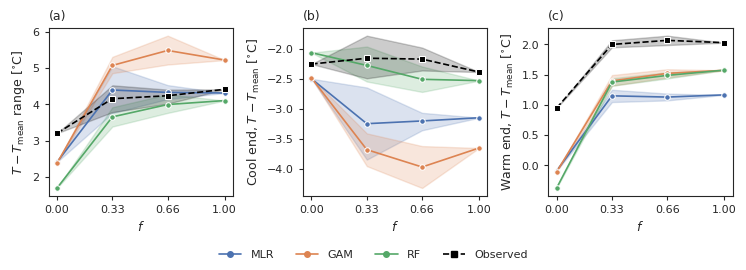

In [13]:
# Spread of the predicted anomaly over the prediction grid, against the spread observed
# among the stations the model was trained on: the 5th-95th percentile range, and its
# cool (5th percentile) and warm (95th percentile) ends separately, so that the
# direction in which the predictions depart from the observations is visible.
# ACHTUNG: the anomaly is referenced to the mean of the stations of each draw, so its
# zero point moves with f. The range is invariant to that reference, but the ends are
# not: they are re-expressed relative to the full-network station mean, which makes
# them comparable across fractions and against the observations.
# All series are shown as the mean across subsampling repetitions with a seeded
# bootstrap 95% confidence interval, which collapses at f=0 and f=1 where every rep
# fits the same stations.
PCTS = (5, 95)
# the three panels span the widened text block of the article
FIGSIZE = (plot_utils.WIDE_TEXT_WIDTH, 2.6)  # in

# Replays the LCS draw of lur-model: a single generator is consumed across the whole
# fraction loop, so the draws only match if the loop is repeated verbatim - and station
# 534, co-located with Zurich-Kaserne, is excluded there and so must be excluded here
# too
train_features_gdf = station_features_gdf[station_features_gdf.index != "534"]
train_aws_gdf = train_features_gdf[train_features_gdf["source"] == "AWS"]
train_lcs_gdf = train_features_gdf[train_features_gdf["source"] == "LCS"]

ts_df = (
    pd.read_csv(ts_df_filepath, index_col=["heatwave", "time"], parse_dates=["time"])
    .rename_axis(columns=train_features_gdf.index.name)
    .droplevel("heatwave")
)
# timestamps are in UTC, select the target hour in local time
ts_df = ts_df.loc[
    ts_df.index.get_level_values("time")
    .tz_localize("UTC")
    .tz_convert("Europe/Zurich")
    .hour
    == target_hour
][train_features_gdf.index]
full_mean_ser = ts_df.mean(axis="columns")
# per-station anomaly relative to the full-network mean
full_anom_ser = ts_df.sub(full_mean_ser, axis="index").mean()

rng = np.random.default_rng(seed)
draw_rows = []
for frac in fracs:
    if np.isclose(frac, 1):
        # every rep trains on the whole network, mirroring how lur-model expands its f=1
        # trial to n_reps (with a single row the bootstrap interval would be undefined)
        full_gdf = pd.concat([train_aws_gdf, train_lcs_gdf])
        samples = [(rep, full_gdf) for rep in range(n_reps)]
    else:
        samples = [
            (
                rep,
                pd.concat(
                    [train_aws_gdf, train_lcs_gdf.sample(frac=frac, random_state=rng)]
                ),
            )
            for rep in range(n_reps)
        ]
    for rep, sample_gdf in samples:
        draw_ts_df = ts_df[sample_gdf.index]
        # shift from the draw's reference to the full-network one, averaged over the
        # (station, time) rows the model is trained on
        weight_ser = draw_ts_df.notna().sum(axis="columns")
        offset = float(
            ((draw_ts_df.mean(axis="columns") - full_mean_ser) * weight_ser).sum()
            / weight_ser.sum()
        )
        obs_lo, obs_hi = np.percentile(full_anom_ser[sample_gdf.index], PCTS)
        draw_rows.append(
            {
                "frac": float(frac),
                "rep": rep,
                "offset": offset,
                "p5": obs_lo,
                "p95": obs_hi,
            }
        )
obs_df = pd.DataFrame(draw_rows)
obs_df["spread"] = obs_df["p95"] - obs_df["p5"]

# predicted percentiles per (model, frac, rep), taken on each rep's own surface by
# lur-model, shifted to the full-network reference
pct_df = pd.read_csv(grid_pred_pct_filepath).merge(
    obs_df[["frac", "rep", "offset"]], on=["frac", "rep"]
)
pct_df["p5"] += pct_df["offset"]
pct_df["p95"] += pct_df["offset"]
pct_df["spread"] = pct_df["p95"] - pct_df["p5"]

panels = {
    "spread": r"$T - T_{\mathrm{mean}}$ range [$^{\circ}$C]",
    "p5": r"Cool end, $T - T_{\mathrm{mean}}$ [$^{\circ}$C]",
    "p95": r"Warm end, $T - T_{\mathrm{mean}}$ [$^{\circ}$C]",
}
fig, axes = plt.subplots(1, len(panels), figsize=FIGSIZE, layout="constrained")
palette = dict(zip(MODEL_KEYS, sns.color_palette(n_colors=len(MODEL_KEYS))))
line_kws = dict(
    marker="o",
    markersize=4,
    errorbar=("ci", 95),
    err_style="band",
    err_kws={"alpha": 0.2},
    seed=seed,
    legend=False,
)
for ax, (col, label) in zip(axes, panels.items()):
    sns.lineplot(
        data=pct_df,
        x="frac",
        y=col,
        hue="model",
        hue_order=MODEL_KEYS,
        palette=palette,
        ax=ax,
        **line_kws,
    )
    sns.lineplot(
        data=obs_df,
        x="frac",
        y=col,
        color="black",
        linestyle="--",
        ax=ax,
        **{**line_kws, "marker": "s"},
    )
    ax.set_xlabel("$f$")
    ax.set_ylabel(label)
    ax.set_xticks(fracs)
handles = [
    plt.Line2D([], [], color=palette[m], marker="o", markersize=4, label=m)
    for m in MODEL_KEYS
]
handles.append(
    plt.Line2D(
        [],
        [],
        color="black",
        linestyle="--",
        marker="s",
        markersize=4,
        label="Observed",
    )
)
fig.legend(
    handles=handles, loc="outside lower center", ncol=len(handles), frameon=False
)
plot_utils.label_panels(axes)
fig.savefig(dst_pred_spread_filepath)

print(
    "reference offset by frac:",
    obs_df.groupby("frac")["offset"].mean().round(2).to_dict(),
)
print(pct_df.groupby(["model", "frac"])[list(panels)].mean().round(2).unstack(0))
print(obs_df.groupby("frac")[list(panels)].mean().round(2))